# 10 · Spark performance evaluation: what distributed processing buys this project
**DS 5110 Big Data Systems — Final Project: Trench Play (OL and DL)**

**What this notebook does**
Measures, on this project's own data and workloads, the Spark design choices taught in DS 5110 — and how much each one is worth in run time, bytes read or bytes shuffled. Every experiment reruns a real step of notebooks 01–06.

| # | Experiment | Course module | Pipeline step it tests |
|---|---|---|---|
| E1 | Explicit schema vs `inferSchema`; splittable vs `multiLine` CSV | M3 data ingestion | 01 reading the raw CSVs |
| E2 | CSV vs Parquet: size on disk, query time, bytes read (column pruning, predicate pushdown) | M3 columnar formats | 01 → every later notebook reads Parquet |
| E3 | Partition pruning: `season=` folders vs one unpartitioned table | M3 partition discovery, M4 partitioning | 01 `partitionBy("season")` / `("drill_type")` |
| E4 | Strong scaling: 1 → all cores on three workloads, against a pandas single-core baseline; Amdahl fit | M1 / M2 parallelism, driver + executors | 01 CSV scan, 04 window step, 06 GBT fit |
| E5 | Shuffle partitions (split size trade-off) and Adaptive Query Execution | M1 MapReduce splits / shuffle | 04 window step |
| E6 | `cache()` for a DataFrame reused by several actions | M2 persist / cache, lineage | 03 / 04 feature tables |
| E7 | Broadcast hash join vs sort-merge (shuffle) join | M2 shuffle cost | 01 cohort filter join |
| E8 | Data skew: partitioning by player (hot keys) vs by snap; window vs two-stage aggregate + broadcast | M5 skew and hot spots | 03 / 04 keys |
| E9 | RDD (Python lambdas) vs DataFrame (Catalyst + Tungsten) for the same aggregation | M2 RDDs vs M3 DataFrames | any per-player summary |
| E10 | `CrossValidator(parallelism=k)`; sparse feature vectors | M6 sparsity, M8 tuning, M9 data parallelism | 06 training |
| E11 | Structured Streaming replay of the tracking frames (micro-batches, throughput) | M11 stream processing | future: live in-game metrics |

**How it measures.** Each timing is the median of `PERF_REPEATS` runs after one warm-up run, ended by an action that forces the full computation. Bytes read / shuffled and task counts come from Spark's own monitoring REST API (the same numbers as the Spark UI), per job group.

**Run on Rivanna** (16 cores) for meaningful scaling numbers: it is part of `run_pipeline.slurm` and takes roughly 20–40 minutes. Environment variables: `PERF_REPEATS` (default 3), `PERF_CORES` (default `1,2,4,8,16`, capped at the cores you have), `QUICK=1` (one raw file, fewer settings: a code test), `PERF_STREAMING=0` to skip E11.

**Inputs:** raw `game_tracking_*.csv`, `player_play.csv`; `processed/line_game_tracking.parquet`, `line_players.parquet`, `task_dl_pressure.parquet`, `outputs/feature_sets.json`.
**Outputs:** `outputs/tables/10_*.csv`, `outputs/figures/10_*.png`. Temporary benchmark files go to `processed/perf_tmp/` and are deleted at the end.

In [1]:
import sys, os, time, json, shutil, statistics, urllib.request
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np, pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image
from pyspark.sql import SparkSession, functions as F
from pyspark.sql.window import Window
from pyspark.sql.types import StructType, StructField, IntegerType, LongType, DoubleType, StringType
import config as C

QUICK = os.environ.get("QUICK", "0") == "1"
REPEATS = int(os.environ.get("PERF_REPEATS", "1" if QUICK else "3"))
AVAIL = int(os.environ.get("SLURM_CPUS_PER_TASK", len(os.sched_getaffinity(0)) if hasattr(os, "sched_getaffinity") else os.cpu_count()))
CORES = sorted({c for c in (int(x) for x in os.environ.get("PERF_CORES", "1,2,4,8,16").split(",")) if c <= AVAIL} | {AVAIL})
if QUICK: CORES = sorted({1, AVAIL})
MAXC = max(CORES)
STREAMING = os.environ.get("PERF_STREAMING", "1") == "1"
TMP = C.PROCESSED_DIR / "perf_tmp"
shutil.rmtree(TMP, ignore_errors=True); TMP.mkdir(parents=True)
print(f"cores available {AVAIL} | core settings {CORES} | repeats {REPEATS} | quick {QUICK}")

# palette: categorical slots in fixed order; inks
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED = ("#257de0", "#f47230", "#00b894", "#f2a600",
                                                           "#ee7fac", "#008a17", "#6a4ce2", "#ec4647")
INK, INK2, GRID = "#191919", "#666666", "#e5e5e5"
plt.rcParams.update({"font.size": 9, "axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2,
                     "ytick.color": INK2, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110, "savefig.dpi": 200,
                     "legend.frameon": False})

def show(fig, name):
    """Save a figure to outputs/figures and show the saved PNG in the notebook."""
    path = C.FIG_DIR / name
    fig.savefig(path, facecolor="white"); plt.close(fig)
    display(Image(str(path), width=1000))

cores available 16 | core settings [1, 2, 4, 8, 16] | repeats 3 | quick False


## 0. Measurement helpers
* `new_spark(cores, **conf)` restarts Spark with `local[cores]` and any extra settings (the JVM stays up; only the SparkContext is rebuilt).
* `measure(tag, fn)` runs a warm-up and `REPEATS` timed runs inside a Spark **job group**, then asks the monitoring REST API for that group's jobs and stages: tasks, input bytes, shuffle bytes, per-task durations.

In [2]:
_spark = None
def new_spark(cores=MAXC, **conf):
    global _spark
    if _spark is not None:
        _spark.stop(); time.sleep(1)
    b = (SparkSession.builder.appName(f"10_perf_{cores}c").master(f"local[{cores}]")
         .config("spark.driver.memory", os.environ.get("SPARK_DRIVER_MEMORY", "6g"))
         .config("spark.sql.shuffle.partitions", os.environ.get("SPARK_SHUFFLE_PARTITIONS", "32"))
         .config("spark.sql.session.timeZone", "UTC").config("spark.sql.ansi.enabled", "false")
         .config("spark.sql.execution.arrow.pyspark.enabled", "false").config("spark.ui.showConsoleProgress", "false")
         .config("spark.ui.enabled", "true").config("spark.ui.retainedJobs", "5000").config("spark.ui.retainedStages", "5000")
         .config("spark.sql.ui.retainedExecutions", "2000"))
    for k, v in conf.items():
        b = b.config(k.replace("__", "."), str(v))
    _spark = b.getOrCreate()
    _spark.sparkContext.setLogLevel("ERROR")
    return _spark

_no_proxy = urllib.request.build_opener(urllib.request.ProxyHandler({}))
def rest(spark, path):
    """GET from Spark's monitoring REST API (same data as the Spark UI)."""
    url = spark.sparkContext.uiWebUrl
    if not url: return None
    port = url.rsplit(":", 1)[1]
    try:
        with _no_proxy.open(f"http://localhost:{port}/api/v1/applications/{spark.sparkContext.applicationId}/{path}", timeout=20) as r:
            return json.loads(r.read())
    except Exception:
        return None

def group_metrics(spark, group, task_durations=False):
    """Tasks, bytes and (optionally) per-task durations of every job run under one job group."""
    for _ in range(10):                       # the UI's listener lags a little behind job completion
        jobs = rest(spark, "jobs") or []
        mine = [j for j in jobs if j.get("jobGroup") == group]
        if mine and all(j["status"] != "RUNNING" for j in mine): break
        time.sleep(0.5)
    stage_ids = sorted({s for j in mine for s in j.get("stageIds", [])})
    out = dict(jobs=len(mine), stages=0, tasks=0, input_mb=0.0, shuffle_write_mb=0.0, shuffle_read_mb=0.0, task_ms=[])
    for sid in stage_ids:
        for st in rest(spark, f"stages/{sid}") or []:
            if st.get("status") != "COMPLETE": continue
            out["stages"] += 1; out["tasks"] += st.get("numCompleteTasks", 0)
            out["input_mb"] += st.get("inputBytes", 0) / 1e6
            out["shuffle_write_mb"] += st.get("shuffleWriteBytes", 0) / 1e6
            out["shuffle_read_mb"] += st.get("shuffleReadBytes", 0) / 1e6
            if task_durations:
                tl = rest(spark, f"stages/{sid}/{st['attemptId']}/taskList?length=100000") or []
                out["task_ms"].append([t.get("duration", 0) for t in tl])
    return out

RESULTS = []
def measure(exp, variant, fn, spark, repeats=REPEATS, warmup=True, task_durations=False, **extra):
    """Median wall time of fn() over `repeats` runs (after a warm-up), plus Spark metrics of one run."""
    sc = spark.sparkContext
    if warmup:
        sc.setJobGroup(f"warm_{exp}_{variant}", "warm-up"); fn()
    times = []
    for i in range(repeats):
        tag = f"{exp}|{variant}|{i}"
        sc.setJobGroup(tag, f"{exp} {variant}")
        t0 = time.perf_counter(); fn(); times.append(time.perf_counter() - t0)
    m = group_metrics(spark, tag, task_durations)          # metrics of the last timed run
    sc.setJobGroup("other", "other")
    row = dict(experiment=exp, variant=variant, seconds=statistics.median(times), seconds_min=min(times),
               runs=len(times), cores=sc.defaultParallelism, **{k: v for k, v in m.items() if k != "task_ms"}, **extra)
    RESULTS.append(row)
    print(f"{exp:<4} {variant:<44} {row['seconds']:7.2f} s  | tasks {row['tasks']:>5}  in {row['input_mb']:8.1f} MB  "
          f"shuffle {row['shuffle_write_mb']:8.1f} MB")
    return (row, m["task_ms"]) if task_durations else row

def ratio(exp, slow, fast):
    r = pd.DataFrame(RESULTS).query("experiment == @exp").set_index("variant").seconds
    return r[slow] / r[fast]

spark = new_spark(MAXC)
print("Spark", spark.version, "| UI:", spark.sparkContext.uiWebUrl, "| REST ok:", rest(spark, "jobs") is not None)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
/apps/software/standard/core/spark/4.2.0/python/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


26/11/25 23:43:08 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark 4.2.0 | UI: http://udc-ba05-19c1:4040 | REST ok: True


## E1 · Reading CSV: explicit schema vs `inferSchema`, and splittable reads (M3)
With `inferSchema=True`, Spark first runs an extra job that reads the file to guess every column's type, then reads it again. An explicit `StructType` skips that pass and fixes the types. A second ingestion detail: `multiLine=True` (needed for `player_play.csv`, whose play descriptions contain quoted line breaks) makes a CSV **non-splittable**, so one file = one task no matter how many cores there are.

In [3]:
I_, L_, D_, S_ = IntegerType(), LongType(), DoubleType(), StringType()
GT_SCHEMA = StructType([StructField(n, t, True) for n, t in [("game_id", L_), ("play_id", I_), ("nfl_id", I_), ("time", S_),
    ("x", D_), ("y", D_), ("s", D_), ("a", D_), ("dis", D_), ("o", D_), ("dir", D_), ("event", S_)]])
gt_files = C.game_tracking_files()
csv_file = max(gt_files, key=lambda f: Path(f).stat().st_size)           # largest raw tracking file
scan_files = [csv_file] if QUICK else gt_files
csv_mb = Path(csv_file).stat().st_size / 1e6
print(f"E1/E2 file: {Path(csv_file).name} ({csv_mb:.0f} MB) | E4 scan: {len(scan_files)} file(s), "
      f"{sum(Path(f).stat().st_size for f in scan_files)/1e9:.2f} GB")

def read_gt_csv(schema=True, files=None):
    r = spark.read.option("header", True).option("nullValue", "NA")
    r = r.schema(GT_SCHEMA) if schema else r.option("inferSchema", True)
    return r.csv(files or csv_file)

e1_inf = measure("E1", "inferSchema=True", lambda: read_gt_csv(False).agg(F.avg("s")).collect(), spark, mb=csv_mb)
e1_sch = measure("E1", "explicit StructType", lambda: read_gt_csv(True).agg(F.avg("s")).collect(), spark, mb=csv_mb)
print(f"→ explicit schema is {e1_inf['seconds']/e1_sch['seconds']:.1f}× faster; jobs launched: "
      f"{e1_inf['jobs']} (infer) vs {e1_sch['jobs']} (schema)")
print("types Spark inferred:", dict(read_gt_csv(False).dtypes))

pp_path = C.raw("player_play.csv")
pp_multi = spark.read.option("header", True).option("multiLine", True).option("escape", '"').csv(pp_path)
pp_split = spark.read.option("header", True).csv(pp_path)
split_tbl = pd.DataFrame({"read": ["multiLine=True (correct for quoted line breaks)", "default (splittable, but breaks ~13k records)"],
                          "partitions = tasks": [pp_multi.rdd.getNumPartitions(), pp_split.rdd.getNumPartitions()],
                          "rows": [pp_multi.count(), pp_split.count()]})
split_tbl

E1/E2 file: game_tracking_2025.csv (1023 MB) | E4 scan: 3 file(s), 2.08 GB


E1   inferSchema=True                                2.06 s  | tasks    34  in   2048.7 MB  shuffle      0.0 MB


E1   explicit StructType                             0.61 s  | tasks    17  in   1024.3 MB  shuffle      0.0 MB
→ explicit schema is 3.4× faster; jobs launched: 4 (infer) vs 2 (schema)


types Spark inferred: {'game_id': 'int', 'play_id': 'int', 'nfl_id': 'int', 'time': 'timestamp', 'x': 'double', 'y': 'double', 's': 'double', 'a': 'double', 'dis': 'double', 'o': 'double', 'dir': 'double', 'event': 'string'}


,read,partitions = tasks,rows
0,multiLine=True (correct for quoted line breaks),1,314197
1,"default (splittable, but breaks ~13k records)",16,327019


## E2 · CSV vs Parquet (M3)
The same raw tracking file is written once as Parquet (columnar, snappy-compressed). Three queries the pipeline actually runs are then timed on both formats:
* **Q1 full scan** — count every frame;
* **Q2 two columns** — mean speed per player (only `nfl_id`, `s` are needed: Parquet reads just those column chunks = *column pruning*);
* **Q3 selective filter** — count snap events (`event = 'ball_snap'`: the filter is *pushed down* to the Parquet reader, which skips row groups using their min/max statistics).

In [4]:
pq_path = str(TMP / "gt_one_file.parquet")
t0 = time.perf_counter(); read_gt_csv(True).write.mode("overwrite").parquet(pq_path); t_write = time.perf_counter() - t0
pq_mb = sum(f.stat().st_size for f in Path(pq_path).rglob("*.parquet")) / 1e6
print(f"CSV {csv_mb:.0f} MB → Parquet {pq_mb:.0f} MB ({csv_mb/pq_mb:.1f}× smaller), written in {t_write:.1f} s")
csv_df, pq_df = read_gt_csv(True), spark.read.parquet(pq_path)
queries = {"Q1 full scan: count()": lambda d: d.count(),
           "Q2 2 of 12 columns: avg(s) by player": lambda d: d.groupBy("nfl_id").agg(F.avg("s")).collect(),
           "Q3 filter event = ball_snap": lambda d: d.filter(F.col("event") == "ball_snap").count()}
for q, fn in queries.items():
    measure("E2", f"CSV  · {q}", lambda: fn(csv_df), spark, query=q, fmt="CSV")
    measure("E2", f"Parquet · {q}", lambda: fn(pq_df), spark, query=q, fmt="Parquet")
print("\nParquet plan for Q2 / Q3 (note ReadSchema and PushedFilters):")
for ln in pq_df.filter(F.col("event") == "ball_snap").select("nfl_id", "s")._jdf.queryExecution().executedPlan().toString().splitlines():
    if "FileScan" in ln: print(ln.strip()[:400])

CSV 1023 MB → Parquet 187 MB (5.5× smaller), written in 3.9 s


E2   CSV  · Q1 full scan: count()                    0.22 s  | tasks    17  in   1024.3 MB  shuffle      0.0 MB


E2   Parquet · Q1 full scan: count()                 0.06 s  | tasks    17  in      0.1 MB  shuffle      0.0 MB


E2   CSV  · Q2 2 of 12 columns: avg(s) by player     0.75 s  | tasks    17  in   1024.3 MB  shuffle      0.2 MB


E2   Parquet · Q2 2 of 12 columns: avg(s) by player    0.11 s  | tasks    17  in      0.1 MB  shuffle      0.2 MB


E2   CSV  · Q3 filter event = ball_snap              0.52 s  | tasks    17  in   1024.3 MB  shuffle      0.0 MB


E2   Parquet · Q3 filter event = ball_snap           0.08 s  | tasks    17  in      1.4 MB  shuffle      0.0 MB

Parquet plan for Q2 / Q3 (note ReadSchema and PushedFilters):
+- FileScan parquet [nfl_id#832,s#836,event#841] Batched: true, DataFilters: [isnotnull(event#841), (event#841 = ball_snap)], Format: Parquet, Location: InMemoryFileIndex(1 paths)[file:/scratch/xdy6sg/ds5110_line_play/processed/perf_tmp/gt_one_file.p..., PartitionFilters: [], PushedFilters: [IsNotNull(event), EqualTo(event,ball_snap)], ReadSchema: struct<nfl_id:int,s:double,event:string>


## E3 · Partition pruning (M3 partition discovery)
Notebook 01 writes the 12M in-game frames into `season=2023 / 2024 / 2025` folders. A query for one season then lists only that folder (`PartitionFilters` in the plan). Compared with the same data written as one unpartitioned table.

In [5]:
lgt_path = C.p("line_game_tracking.parquet")
flat_path = str(TMP / "line_game_tracking_flat.parquet")
spark.read.parquet(lgt_path).repartition(3 * MAXC).write.mode("overwrite").parquet(flat_path)   # seasons mixed in every file, as unsorted data would be
part_df, flat_df = spark.read.parquet(lgt_path), spark.read.parquet(flat_path)
q_season = lambda d: d.filter(F.col("season") == 2025).groupBy("nfl_id").agg(F.max("s")).collect()
measure("E3", "unpartitioned table, filter season = 2025", lambda: q_season(flat_df), spark)
measure("E3", "season= folders, filter season = 2025", lambda: q_season(part_df), spark)
for ln in part_df.filter(F.col("season") == 2025).select("s")._jdf.queryExecution().executedPlan().toString().splitlines():
    if "FileScan" in ln: print("PartitionFilters:", ln.split("PartitionFilters:")[1].split("]")[0] + "]")

E3   unpartitioned table, filter season = 2025       0.15 s  | tasks    17  in      0.8 MB  shuffle      0.1 MB


E3   season= folders, filter season = 2025           0.19 s  | tasks    17  in      0.1 MB  shuffle      0.0 MB
PartitionFilters:  [isnotnull(season#1315), (season#1315 = 2025)]


## E4 · Strong scaling: same work, more cores (M1 / M2)
Spark is restarted with `local[1]`, `local[2]`, … and three real workloads are timed:
* **W1 CSV scan + aggregate** (notebook 01): parse every raw tracking CSV, mean / max speed per player;
* **W2 window step** (notebook 04): snap alignment + window functions + per-snap aggregation over 12M frames (two shuffles);
* **W3 model fit** (notebook 06): Gradient-boosted trees on the DL pass-rush task.

Speedup = T(1 core) / T(p cores). An **Amdahl's-law** fit, T(p) = T(1)·(s + (1 − s)/p), estimates the serial share *s* of each workload (driver work, task scheduling, Python ↔ JVM calls). W1 is also run single-threaded in **pandas**, the non-Spark alternative.

In [6]:
def w1_scan(sp):
    d = sp.read.option("header", True).option("nullValue", "NA").schema(GT_SCHEMA).csv(scan_files)
    return lambda: d.groupBy("nfl_id").agg(F.avg("s"), F.max("s"), F.count("*")).collect()

def snap_metrics(sp):
    gt = sp.read.parquet(lgt_path)
    key = ["game_id", "play_id", "nfl_id"]
    snap = gt.filter(F.col("event") == "ball_snap").groupBy(*key).agg(F.min(F.col("ts").cast("double")).alias("snap_t"))
    w = Window.partitionBy(*key).orderBy("ts")
    g = (gt.join(snap, key).withColumn("t_rel", F.round(F.col("ts").cast("double") - F.col("snap_t"), 2))
           .filter((F.col("t_rel") >= 0) & (F.col("t_rel") <= 1.5))
           .withColumn("s_sm", F.avg("s").over(w.rowsBetween(-1, 1)))
           .withColumn("step", F.sqrt((F.col("x") - F.lag("x").over(w)) ** 2 + (F.col("y") - F.lag("y").over(w)) ** 2)))
    return g.groupBy(*key).agg(F.max("s_sm").alias("s_max"), F.sum("step").alias("d15"),
                               F.max(F.when(F.col("t_rel") <= 1.0, F.col("s_sm"))).alias("s10"))

def w2_window(sp):
    mv = snap_metrics(sp)
    return lambda: mv.agg(F.count("*"), F.sum("s_max"), F.sum("d15"), F.sum("s10")).collect()   # forces every column

fs = json.load(open(C.OUTPUT_DIR / "feature_sets.json"))
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, Imputer, VectorAssembler, StandardScaler
from pyspark.ml.classification import GBTClassifier, LogisticRegression
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder
CAT, NUM = fs["context_cat"], fs["context_num"] + fs["trk"] + fs["size"]
def feature_stages(scale=True):
    st = [StringIndexer(inputCols=CAT, outputCols=[f"{c}_i" for c in CAT], handleInvalid="keep"),
          OneHotEncoder(inputCols=[f"{c}_i" for c in CAT], outputCols=[f"{c}_o" for c in CAT], handleInvalid="keep"),
          Imputer(inputCols=NUM, outputCols=[f"{c}_m" for c in NUM], strategy="median"),
          VectorAssembler(inputCols=[f"{c}_o" for c in CAT] + [f"{c}_m" for c in NUM], outputCol="features_raw")]
    if scale: st.append(StandardScaler(inputCol="features_raw", outputCol="features", withMean=True, withStd=True))
    return st
def load_task(sp):
    d = sp.read.parquet(C.p("task_dl_pressure.parquet")).filter("split = 'train'")
    for c in NUM: d = d.withColumn(c, F.col(c).cast("double"))
    return d.withColumn("label", F.col("target").cast("double")).cache()

def w3_fit(sp):
    d = load_task(sp); d.count()
    pipe = Pipeline(stages=feature_stages(False) + [GBTClassifier(featuresCol="features_raw", labelCol="label",
                    weightCol="weight", maxIter=10 if QUICK else 30, maxDepth=3, seed=C.SEED)])
    return lambda: pipe.fit(d)

WORK = {"W1 CSV scan + aggregate (notebook 01)": w1_scan, "W2 window step, 12M frames (notebook 04)": w2_window,
        "W3 GBT fit, DL pass rush (notebook 06)": w3_fit}
for p in CORES:
    sp = new_spark(p)
    for name, make in WORK.items():
        measure("E4", f"{name} · {p} cores", make(sp), sp, workload=name, p=p)
spark = new_spark(MAXC)

# pandas baseline for W1 (single core, reads only the 2 needed columns)
t0 = time.perf_counter()
pdf = pd.concat([pd.read_csv(f, usecols=["nfl_id", "s"], na_values="NA") for f in scan_files])
_ = pdf.groupby("nfl_id").s.agg(["mean", "max", "count"])
t_pandas = time.perf_counter() - t0
mem_gb = pdf.memory_usage(deep=True).sum() / 1e9
del pdf; import gc; gc.collect()
RESULTS.append(dict(experiment="E4", variant="W1 pandas read_csv + groupby · 1 core", seconds=t_pandas, seconds_min=t_pandas,
                    runs=1, cores=1, workload="W1 CSV scan + aggregate (notebook 01)", p=1, engine="pandas"))
print(f"pandas W1: {t_pandas:.1f} s, {mem_gb:.2f} GB in memory for just 2 columns")

E4   W1 CSV scan + aggregate (notebook 01) · 1 cores   17.38 s  | tasks    17  in   2076.9 MB  shuffle      0.2 MB


E4   W2 window step, 12M frames (notebook 04) · 1 cores    8.83 s  | tasks    11  in      1.0 MB  shuffle    257.1 MB


E4   W3 GBT fit, DL pass rush (notebook 06) · 1 cores    3.25 s  | tasks   189  in    675.7 MB  shuffle      1.9 MB


E4   W1 CSV scan + aggregate (notebook 01) · 2 cores    7.94 s  | tasks    17  in   2076.9 MB  shuffle      0.2 MB


E4   W2 window step, 12M frames (notebook 04) · 2 cores    4.67 s  | tasks    12  in      1.0 MB  shuffle    257.1 MB


E4   W3 GBT fit, DL pass rush (notebook 06) · 2 cores    3.03 s  | tasks   374  in    675.5 MB  shuffle      3.1 MB


... (6 outputs left out)

E4   W1 CSV scan + aggregate (notebook 01) · 16 cores    1.37 s  | tasks    18  in   2077.1 MB  shuffle      0.2 MB


E4   W2 window step, 12M frames (notebook 04) · 16 cores    2.56 s  | tasks    55  in      1.2 MB  shuffle    257.2 MB


E4   W3 GBT fit, DL pass rush (notebook 06) · 16 cores    3.22 s  | tasks  2779  in    655.8 MB  shuffle     14.4 MB


pandas W1: 3.6 s, 0.54 GB in memory for just 2 columns


In [7]:
sc4 = pd.DataFrame([r for r in RESULTS if r["experiment"] == "E4" and r.get("engine") != "pandas"])
def amdahl_s(p, t):
    """Least-squares serial share s for T(p) = T1 * (s + (1 - s) / p), with T1 the measured 1-core time."""
    t1 = t[p == 1][0] if (p == 1).any() else t[0] * p[0]
    grid = np.linspace(0, 1, 1001)
    err = [np.sum((t1 * (s + (1 - s) / p) - t) ** 2) for s in grid]
    return grid[int(np.argmin(err))], t1
scaling = []
for wname, g in sc4.groupby("workload"):
    g = g.sort_values("p"); p_, t_ = g.p.values.astype(float), g.seconds.values
    s_hat, t1 = amdahl_s(p_, t_)
    for pp, tt in zip(p_, t_):
        scaling.append(dict(workload=wname, cores=int(pp), seconds=tt, speedup=t1 / tt, efficiency=t1 / tt / pp,
                            amdahl_serial_share=s_hat, amdahl_max_speedup=(1 / s_hat if s_hat > 0 else np.inf)))
scaling = pd.DataFrame(scaling)
scaling.to_csv(C.TABLE_DIR / "10_core_scaling.csv", index=False)
scaling.round(3)

,workload,cores,seconds,speedup,efficiency,amdahl_serial_share,amdahl_max_speedup
0,W1 CSV scan + aggregate (notebook 01),1,17.375,1.000,1.000,0.000,inf
1,W1 CSV scan + aggregate (notebook 01),2,7.941,2.188,1.094,0.000,inf
2,W1 CSV scan + aggregate (notebook 01),4,4.080,4.259,1.065,0.000,inf
3,W1 CSV scan + aggregate (notebook 01),8,2.113,8.225,1.028,0.000,inf
4,W1 CSV scan + aggregate (notebook 01),16,1.371,12.673,0.792,0.000,inf
5,"W2 window step, 12M frames (notebook 04)",1,8.826,1.000,1.000,0.194,5.155
6,"W2 window step, 12M frames (notebook 04)",2,4.666,1.892,0.946,0.194,5.155
7,"W2 window step, 12M frames (notebook 04)",4,3.283,2.688,0.672,0.194,5.155
8,"W2 window step, 12M frames (notebook 04)",8,2.700,3.269,0.409,0.194,5.155
9,"W2 window step, 12M frames (notebook 04)",16,2.562,3.445,0.215,0.194,5.155


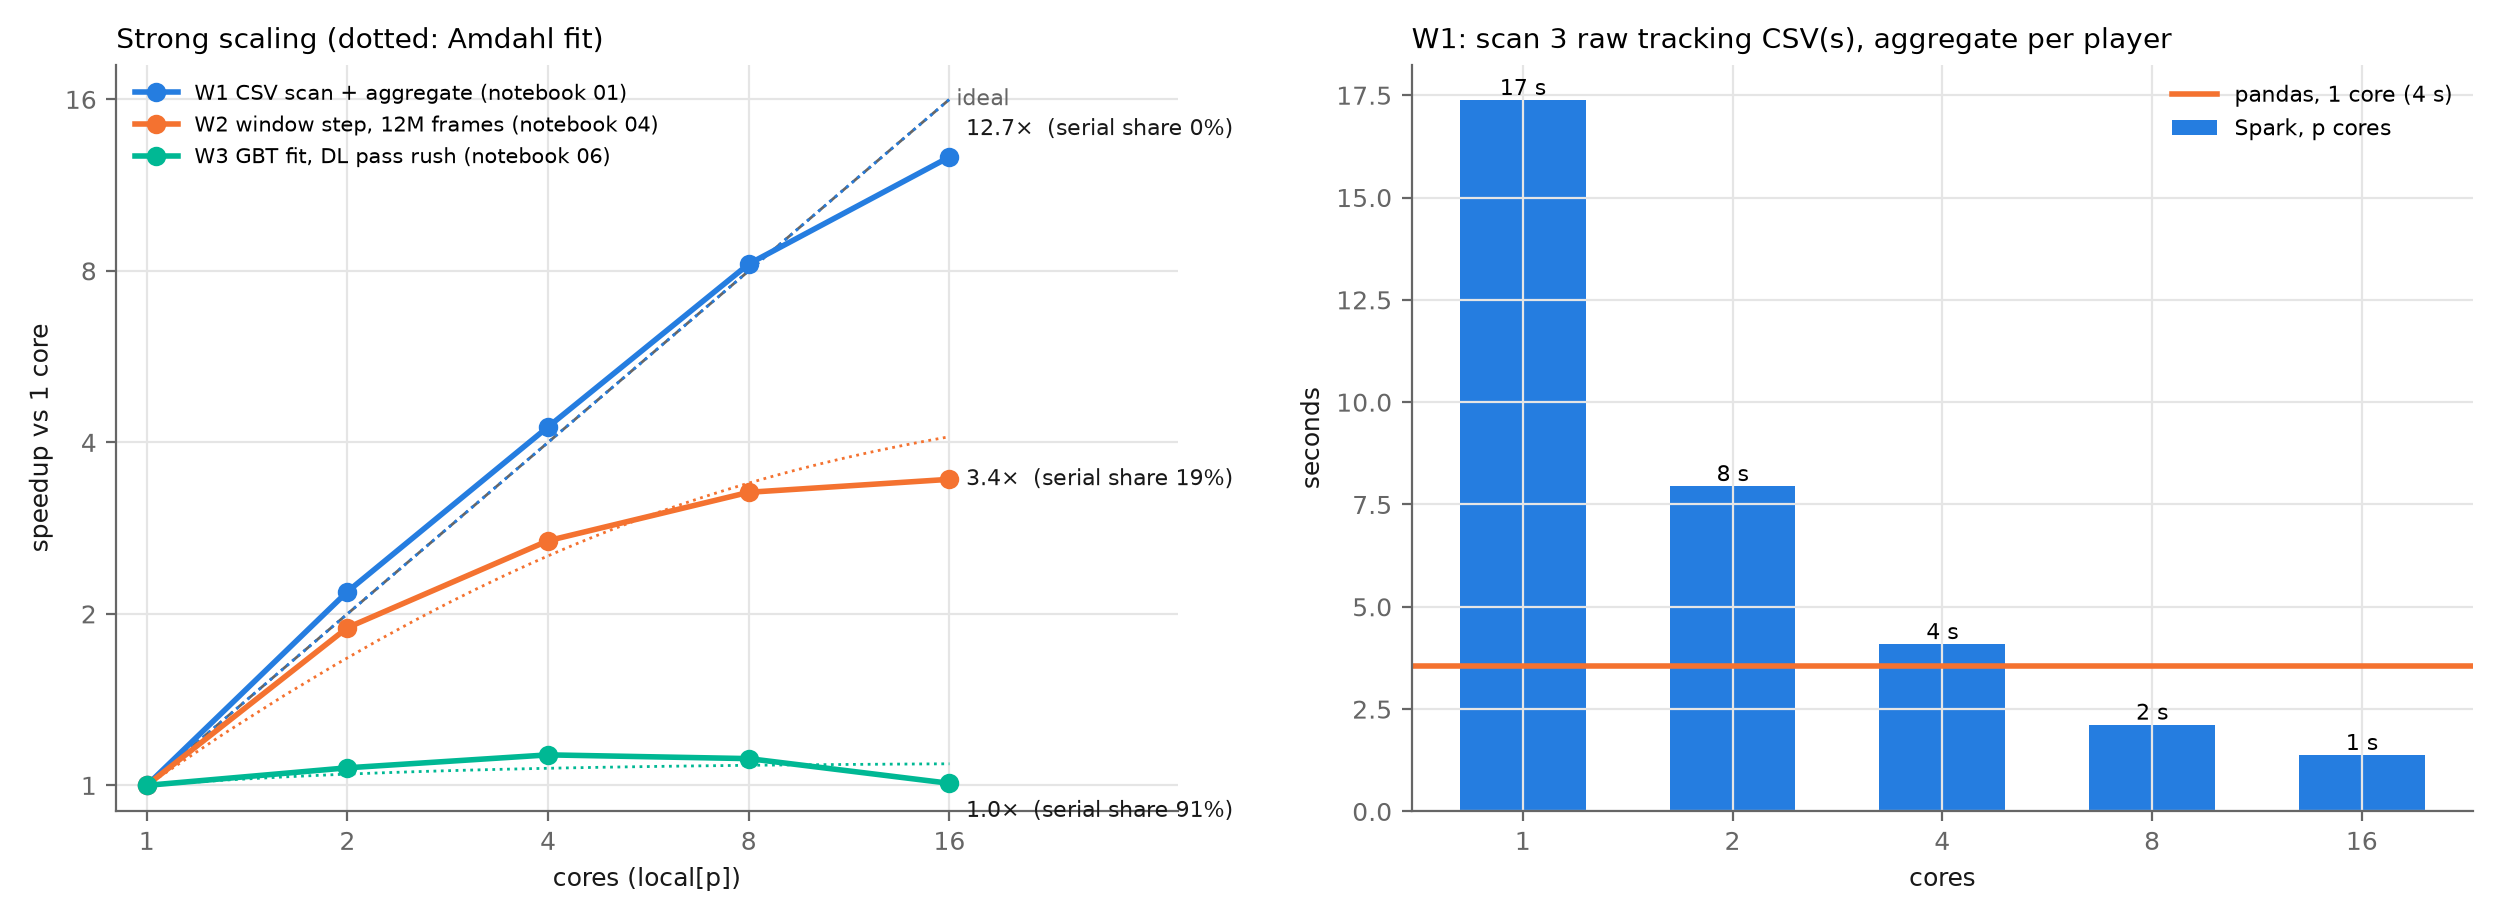

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
wcol = dict(zip(WORK, [BLUE, ORANGE, AQUA]))
ax = axes[0]
pmax = scaling.cores.max()
ax.plot([1, pmax], [1, pmax], color=INK2, lw=1, ls="--"); ax.text(pmax, pmax, " ideal", color=INK2, va="center", fontsize=8)
for k, (wname, g) in enumerate(scaling.groupby("workload")):
    ax.plot(g.cores, g.speedup, marker="o", ms=6, lw=2, color=wcol[wname], label=wname)
    pp = np.linspace(1, pmax, 50); s_ = g.amdahl_serial_share.iloc[0]
    ax.plot(pp, 1 / (s_ + (1 - s_) / pp), color=wcol[wname], lw=1, ls=":")
    ax.annotate(f"{g.speedup.iloc[-1]:.1f}×  (serial share {s_:.0%})", (g.cores.iloc[-1], g.speedup.iloc[-1]),
                xytext=(6, 10 - 10 * k), textcoords="offset points", fontsize=8, color=INK, va="center")
ax.set_xscale("log", base=2); ax.set_yscale("log", base=2)
yt = [t for t in (1, 2, 4, 8, 16, 32, 64) if t <= pmax]
ax.set_xticks(CORES, [str(c) for c in CORES]); ax.set_yticks(yt, [str(t) for t in yt]); ax.set_ylim(0.9, pmax * 1.15)
ax.set_xlim(0.9, pmax * 2.2)
ax.set_xlabel("cores (local[p])"); ax.set_ylabel("speedup vs 1 core"); ax.set_title("Strong scaling (dotted: Amdahl fit)", loc="left", fontsize=10)
ax.legend(fontsize=7.6, loc="upper left")
ax = axes[1]
w1 = scaling[scaling.workload.str.startswith("W1")]
ax.bar([str(c) for c in w1.cores], w1.seconds, color=BLUE, width=0.6, label="Spark, p cores")
ax.axhline(t_pandas, color=ORANGE, lw=2, label=f"pandas, 1 core ({t_pandas:.0f} s)")
for i, (c, s_) in enumerate(zip(w1.cores, w1.seconds)):
    ax.text(i, s_, f"{s_:.0f} s", ha="center", va="bottom", fontsize=8)
ax.set_xlabel("cores"); ax.set_ylabel("seconds"); ax.legend(fontsize=8)
ax.set_title(f"W1: scan {len(scan_files)} raw tracking CSV(s), aggregate per player", loc="left", fontsize=10)
fig.tight_layout(); show(fig, "10_core_scaling.png")

## E5 · Shuffle partitions and Adaptive Query Execution (M1: the split-size trade-off)
The window step (W2) shuffles 12M frames twice. `spark.sql.shuffle.partitions` sets how many reduce tasks receive them: too few → each task is large (less parallelism, possible spill), too many → scheduling overhead dominates ("more splits means less time per split, but the overhead of managing splits starts to dominate"). AQE (on by default since Spark 3.2) measures the shuffle at run time and coalesces small partitions.

In [9]:
SP = [MAXC, 4 * MAXC, 200, 2000] if not QUICK else [MAXC, 200]
SP = sorted(set([max(1, MAXC // 2)] + SP))
for n in SP:
    sp = new_spark(MAXC, spark__sql__shuffle__partitions=n, spark__sql__adaptive__enabled="false")
    measure("E5", f"AQE off · shuffle.partitions = {n}", w2_window(sp), sp, n_shuffle=n, aqe=False)
for n in [200, 2000] if not QUICK else [200]:
    sp = new_spark(MAXC, spark__sql__shuffle__partitions=n, spark__sql__adaptive__enabled="true")
    measure("E5", f"AQE on  · shuffle.partitions = {n}", w2_window(sp), sp, n_shuffle=n, aqe=True)
spark = new_spark(MAXC)
e5 = pd.DataFrame([r for r in RESULTS if r["experiment"] == "E5"])
e5[["variant", "seconds", "tasks", "shuffle_write_mb"]]

E5   AQE off · shuffle.partitions = 8                2.41 s  | tasks    41  in      1.2 MB  shuffle    257.1 MB


E5   AQE off · shuffle.partitions = 16               2.15 s  | tasks    49  in      1.2 MB  shuffle    257.1 MB


E5   AQE off · shuffle.partitions = 64               2.14 s  | tasks    97  in      1.2 MB  shuffle    257.2 MB


E5   AQE off · shuffle.partitions = 200              2.28 s  | tasks   233  in      1.2 MB  shuffle    257.3 MB


E5   AQE off · shuffle.partitions = 2000             3.65 s  | tasks  2033  in      1.2 MB  shuffle    258.7 MB


E5   AQE on  · shuffle.partitions = 200              2.61 s  | tasks    53  in      1.2 MB  shuffle    257.3 MB


E5   AQE on  · shuffle.partitions = 2000             2.52 s  | tasks    54  in      1.2 MB  shuffle    258.6 MB


,variant,seconds,tasks,shuffle_write_mb
0,AQE off · shuffle.partitions = 8,2.405040,41,257.100129
1,AQE off · shuffle.partitions = 16,2.148835,49,257.111849
2,AQE off · shuffle.partitions = 64,2.139594,97,257.155175
3,AQE off · shuffle.partitions = 200,2.278420,233,257.314653
4,AQE off · shuffle.partitions = 2000,3.646356,2033,258.740731
5,AQE on · shuffle.partitions = 200,2.613229,53,257.299821
6,AQE on · shuffle.partitions = 2000,2.522853,54,258.582237


## E6 · Caching a DataFrame that several actions reuse (M2 persist / cache)
Spark recomputes a DataFrame's whole lineage for every action unless it is cached. Notebooks 03 and 04 compute frame-level kinematics once and then derive several summaries from them. Here: the snap-aligned frames (join + windows) followed by three summaries, without and with `cache()`.

In [10]:
def snap_frames(sp):
    gt = sp.read.parquet(lgt_path); key = ["game_id", "play_id", "nfl_id"]
    snap = gt.filter(F.col("event") == "ball_snap").groupBy(*key).agg(F.min(F.col("ts").cast("double")).alias("snap_t"))
    w = Window.partitionBy(*key).orderBy("ts")
    return (gt.join(snap, key).withColumn("t_rel", F.round(F.col("ts").cast("double") - F.col("snap_t"), 2))
              .filter((F.col("t_rel") >= 0) & (F.col("t_rel") <= 1.5))
              .withColumn("s_sm", F.avg("s").over(w.rowsBetween(-1, 1))))
actions = [lambda d: d.groupBy("line_group").agg(F.avg("s_sm")).collect(),
           lambda d: d.filter(F.col("t_rel") == 1.0).groupBy("nfl_id").agg(F.avg("s_sm")).collect(),
           lambda d: d.groupBy("season").agg(F.max("s_sm"), F.count("*")).collect()]
def run_actions(cache):
    def go():
        d = snap_frames(spark)
        if cache: d = d.cache()
        for a in actions: a(d)
        if cache: d.unpersist(blocking=True)
    return go
measure("E6", "no cache: 3 actions recompute the lineage", run_actions(False), spark)
measure("E6", "cache(): computed once, 2 actions read memory", run_actions(True), spark)
d = snap_frames(spark).cache(); d.count()
st = rest(spark, "storage/rdd") or []
cached_mb = sum(s.get("memoryUsed", 0) for s in st) / 1e6
print(f"cached snap frames: {d.count():,} rows, {cached_mb:.0f} MB in executor memory")
d.unpersist(blocking=True)

E6   no cache: 3 actions recompute the lineage       6.27 s  | tasks   165  in      3.7 MB  shuffle    464.8 MB


E6   cache(): computed once, 2 actions read memory    3.82 s  | tasks   295  in    785.5 MB  shuffle    516.4 MB


cached snap frames: 2,791,841 rows, 261 MB in executor memory


DataFrame[game_id: bigint, play_id: int, nfl_id: int, x: double, y: double, s: double, a: double, dis: double, o: double, dir: double, event: string, line_group: string, ts: timestamp, season: int, snap_t: double, t_rel: double, s_sm: double]

## E7 · Broadcast join vs shuffle join (M2)
Joining 12M frames to the 239-row player table: a **broadcast hash join** ships the small table to every task (no shuffle of the big side); a **sort-merge join** shuffles and sorts both sides by `nfl_id`.

In [11]:
lp = spark.read.parquet(C.p("line_players.parquet")).select("nfl_id", F.col("line_group").alias("grp"), "combine_weight")
frames = spark.read.parquet(lgt_path).select("nfl_id", "s")
j_bc = lambda: frames.join(F.broadcast(lp), "nfl_id").groupBy("grp").agg(F.avg("s"), F.avg("combine_weight")).collect()
j_sm = lambda: frames.join(lp.hint("merge"), "nfl_id").groupBy("grp").agg(F.avg("s"), F.avg("combine_weight")).collect()
measure("E7", "sort-merge join (shuffle both sides)", j_sm, spark)
measure("E7", "broadcast hash join", j_bc, spark)
for name, df_ in [("broadcast", frames.join(F.broadcast(lp), "nfl_id")), ("merge", frames.join(lp.hint("merge"), "nfl_id"))]:
    ops = [o for o in ("BroadcastHashJoin", "SortMergeJoin", "Exchange") if o in df_._jdf.queryExecution().executedPlan().toString()]
    print(f"{name:<10} plan contains: {ops}")

E7   sort-merge join (shuffle both sides)            1.09 s  | tasks    37  in      0.5 MB  shuffle     84.0 MB


E7   broadcast hash join                             0.48 s  | tasks    18  in      0.5 MB  shuffle      0.0 MB
broadcast  plan contains: ['BroadcastHashJoin', 'Exchange']
merge      plan contains: ['SortMergeJoin', 'Exchange']


## E8 · Data skew and hot keys (M5)
Snaps are very unevenly spread over players: a starter has thousands of snaps, a backup a few dozen. Any operation keyed by **player alone** sends all of a starter's frames to one task (a hot spot); the pipeline instead keys frame-level work by **(game, play, player)**.
1. Rows per partition after hash-partitioning by each key.
2. The same player-level z-score of speed computed two ways: (a) a window over `partitionBy("nfl_id")` — one task per player's frames; (b) the two-stage remedy: `groupBy` (partial aggregation on every task, like a combiner) then a broadcast join back. Per-task durations come from the REST API.

/apps/software/standard/core/spark/4.2.0/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


frames per player: median 28,752, max 278,149 (10× the median), top 10% of players hold 35% of frames


/apps/software/standard/core/spark/4.2.0/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


by player (nfl_id)             rows per partition: max/median = 3.99


/apps/software/standard/core/spark/4.2.0/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


by snap (game, play, nfl_id)   rows per partition: max/median = 1.05


E8   window partitionBy(nfl_id): hot keys            1.17 s  | tasks    81  in      0.1 MB  shuffle     84.0 MB


E8   groupBy + broadcast join (two-stage)            0.42 s  | tasks    97  in      0.8 MB  shuffle      0.0 MB


reduce-side tasks: window max/median 3.1 (0.2 s longest) | two-stage max/median 2.5


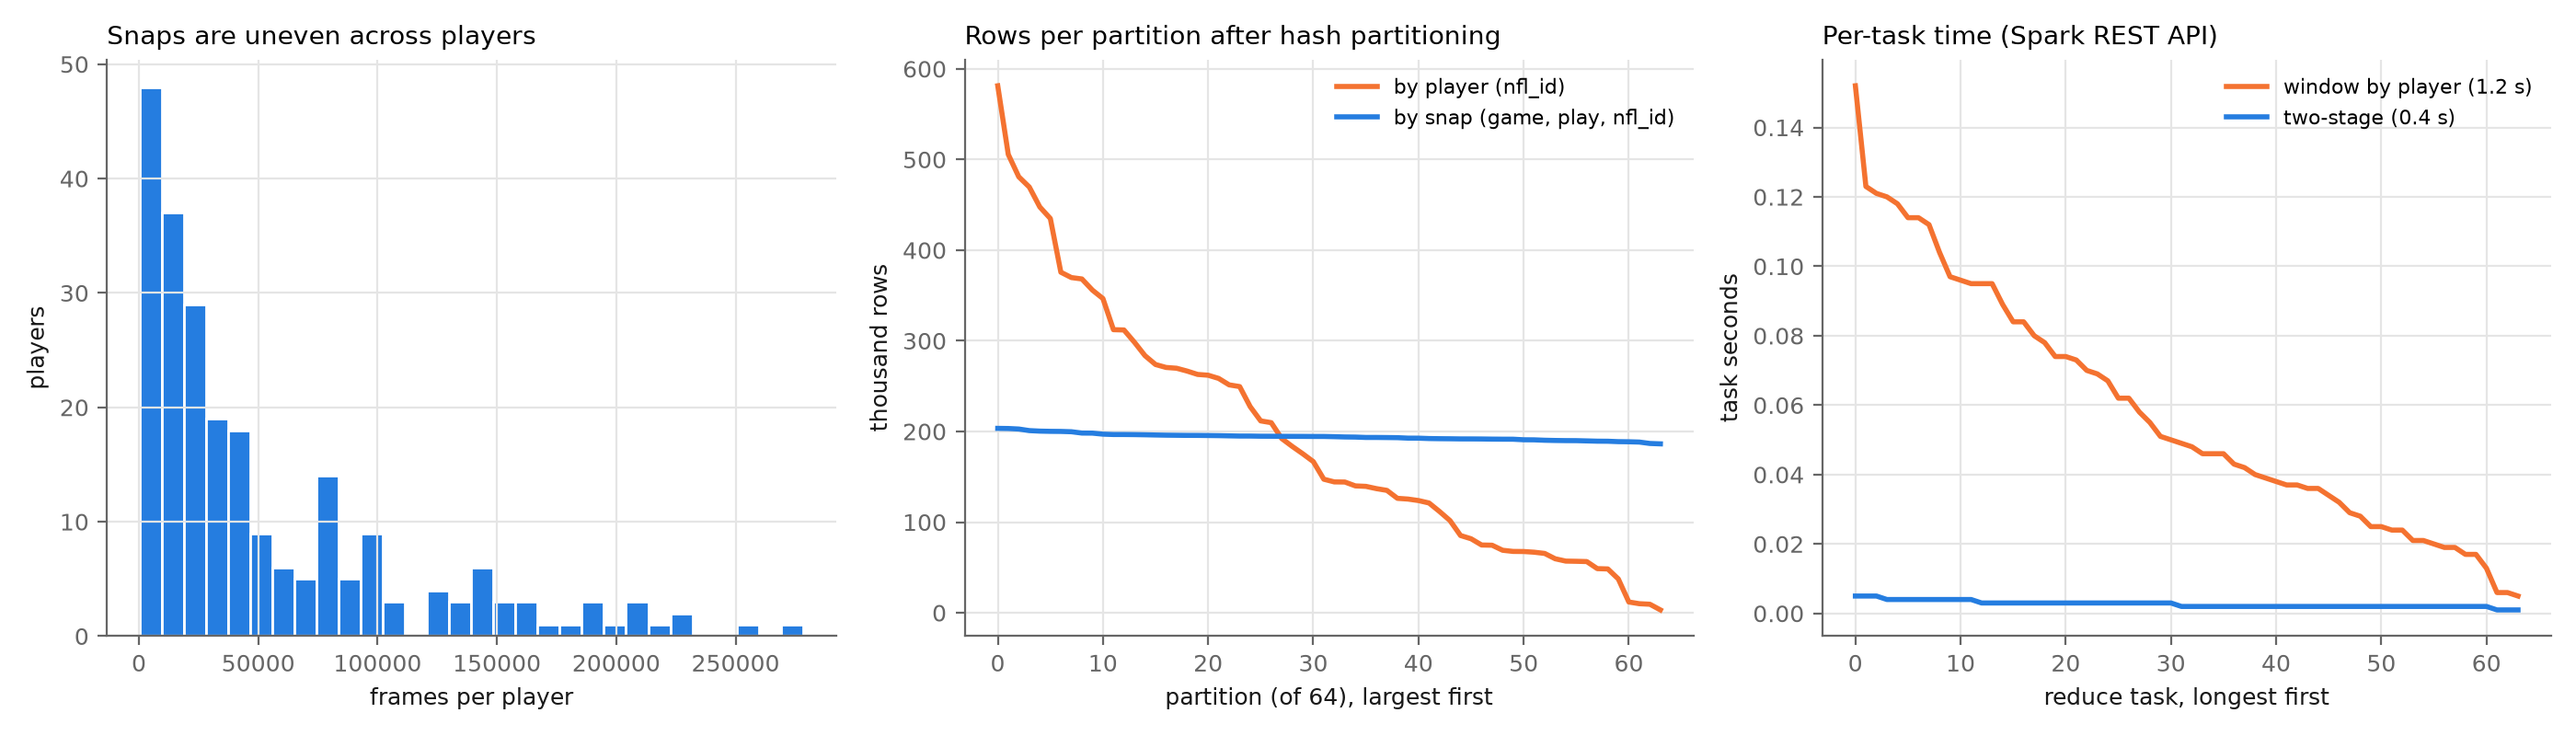

In [12]:
gtf = spark.read.parquet(lgt_path).select("game_id", "play_id", "nfl_id", "s")
per_player = gtf.groupBy("nfl_id").count().toPandas()["count"]
print(f"frames per player: median {per_player.median():,.0f}, max {per_player.max():,.0f} "
      f"({per_player.max()/per_player.median():.0f}× the median), top 10% of players hold "
      f"{per_player.sort_values().iloc[-max(1, len(per_player)//10):].sum()/per_player.sum():.0%} of frames")
P = 4 * MAXC
part_sizes = {}
for lbl, cols in [("by player (nfl_id)", ["nfl_id"]), ("by snap (game, play, nfl_id)", ["game_id", "play_id", "nfl_id"])]:
    part_sizes[lbl] = (gtf.repartition(P, *cols).groupBy(F.spark_partition_id().alias("pid")).count()
                       .toPandas().set_index("pid")["count"].reindex(range(P), fill_value=0).values)
    v = part_sizes[lbl]; print(f"{lbl:<30} rows per partition: max/median = {v.max()/max(np.median(v),1):.2f}")

def z_window():
    w = Window.partitionBy("nfl_id")
    return (gtf.withColumn("z", (F.col("s") - F.avg("s").over(w)) / F.stddev("s").over(w))
               .agg(F.sum(F.abs("z"))).collect())
def z_two_stage():
    stats = gtf.groupBy("nfl_id").agg(F.avg("s").alias("mu"), F.stddev("s").alias("sd"))
    return (gtf.join(F.broadcast(stats), "nfl_id").withColumn("z", (F.col("s") - F.col("mu")) / F.col("sd"))
               .agg(F.sum(F.abs("z"))).collect())
sk = new_spark(MAXC, spark__sql__shuffle__partitions=P, spark__sql__adaptive__enabled="false")
gtf = sk.read.parquet(lgt_path).select("game_id", "play_id", "nfl_id", "s")
r_win, td_win = measure("E8", "window partitionBy(nfl_id): hot keys", z_window, sk, task_durations=True)
r_two, td_two = measure("E8", "groupBy + broadcast join (two-stage)", z_two_stage, sk, task_durations=True)
spark = new_spark(MAXC)
def task_spread(tds):
    """Per-task durations of the widest stage (the reduce side)."""
    if not tds: return np.array([])
    return np.array(max(tds, key=len))
tw, tt = task_spread(td_win), task_spread(td_two)
if len(tw) and len(tt):
    print(f"reduce-side tasks: window max/median {tw.max()/max(np.median(tw),1):.1f} ({tw.max()/1000:.1f} s longest) | "
          f"two-stage max/median {tt.max()/max(np.median(tt),1):.1f}")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
ax = axes[0]
ax.hist(per_player, bins=30, color=BLUE, edgecolor="white", linewidth=1)
ax.set_xlabel("frames per player"); ax.set_ylabel("players"); ax.set_title("Snaps are uneven across players", loc="left", fontsize=10)
ax = axes[1]
for (lbl, v), c in zip(part_sizes.items(), [ORANGE, BLUE]):
    ax.plot(np.arange(P), np.sort(v)[::-1] / 1e3, color=c, lw=2, label=lbl)
ax.set_xlabel(f"partition (of {P}), largest first"); ax.set_ylabel("thousand rows")
ax.set_title("Rows per partition after hash partitioning", loc="left", fontsize=10); ax.legend(fontsize=8)
ax = axes[2]
for v, c, lbl in [(tw, ORANGE, f"window by player ({r_win['seconds']:.1f} s)"), (tt, BLUE, f"two-stage ({r_two['seconds']:.1f} s)")]:
    if len(v): ax.plot(np.arange(len(v)), np.sort(v)[::-1] / 1000, color=c, lw=2, label=lbl)
ax.set_xlabel("reduce task, longest first"); ax.set_ylabel("task seconds")
ax.set_title("Per-task time (Spark REST API)", loc="left", fontsize=10); ax.legend(fontsize=8)
fig.tight_layout(); show(fig, "10_skew.png")

## E9 · RDD vs DataFrame (M2 / M3)
The same per-player mean speed: with the RDD API every row is serialized into a Python worker and the lambdas run in Python; with the DataFrame API Catalyst plans it and the JVM runs it on columnar batches with partial aggregation.

In [13]:
fr = spark.read.parquet(lgt_path).select("nfl_id", "s").filter(F.col("s").isNotNull())
rdd_fn = lambda: (fr.rdd.map(lambda r: (r[0], (r[1], 1))).reduceByKey(lambda a, b: (a[0] + b[0], a[1] + b[1]))
                    .mapValues(lambda v: v[0] / v[1]).collect())
df_fn = lambda: fr.groupBy("nfl_id").agg(F.avg("s")).collect()
measure("E9", "RDD map + reduceByKey (Python lambdas)", rdd_fn, spark)
measure("E9", "DataFrame groupBy().agg(avg)", df_fn, spark)
a = dict(rdd_fn()); b = {r[0]: r[1] for r in df_fn()}
print("same answer:", all(abs(a[k] - b[k]) < 1e-9 for k in b))

E9   RDD map + reduceByKey (Python lambdas)          9.43 s  | tasks    32  in      0.4 MB  shuffle      0.0 MB


E9   DataFrame groupBy().agg(avg)                    0.19 s  | tasks    17  in      0.4 MB  shuffle      0.0 MB


same answer: True


## E10 · Model tuning in parallel and sparse features (M6 / M8 / M9)
`CrossValidator(parallelism=k)` submits k (fold, setting) fits at once; each fit is itself distributed over the data partitions (data parallelism: tasks compute partial gradients on their rows, the driver combines them). Timed for a logistic-regression grid of 4 settings × 5 player-grouped folds on the DL pass-rush task. Then: how sparse the assembled feature vectors are (one-hot context columns).

In [14]:
dtask = load_task(spark); dtask.count()
lr = LogisticRegression(featuresCol="features", labelCol="label", weightCol="weight", maxIter=100)
grid = ParamGridBuilder().addGrid(lr.regParam, [0.0, 0.01, 0.1, 1.0]).build()
ev = BinaryClassificationEvaluator(labelCol="label", metricName="areaUnderROC")
for k in sorted({1, 2, 4, min(8, MAXC)} if not QUICK else {1, 2}):
    cv = CrossValidator(estimator=Pipeline(stages=feature_stages() + [lr]), estimatorParamMaps=grid, evaluator=ev,
                        foldCol="fold", numFolds=C.N_FOLDS, parallelism=k, seed=C.SEED)
    measure("E10", f"CrossValidator parallelism = {k} (20 fits)", lambda: cv.fit(dtask), spark,
            repeats=1 if QUICK else 2, warmup=False, parallelism=k)

fe = Pipeline(stages=feature_stages(False)).fit(dtask).transform(dtask).select("features_raw").toPandas()
size = fe.features_raw.iloc[0].size
nnz = fe.features_raw.map(lambda v: v.numNonzeros())
sparse_tbl = pd.DataFrame({"feature vector length": [size], "mean non-zeros": [nnz.mean()],
                           "share non-zero": [nnz.mean() / size],
                           "bytes dense (8/value)": [8 * size], "bytes sparse (12/non-zero)": [12 * nnz.mean()]}).round(3)
sparse_tbl

E10  CrossValidator parallelism = 1 (20 fits)       33.80 s  | tasks 14103  in   2893.9 MB  shuffle     19.8 MB


E10  CrossValidator parallelism = 2 (20 fits)       19.63 s  | tasks 14178  in   2907.3 MB  shuffle     19.8 MB


E10  CrossValidator parallelism = 4 (20 fits)       16.33 s  | tasks 14328  in   2933.9 MB  shuffle     19.9 MB


E10  CrossValidator parallelism = 8 (20 fits)       16.20 s  | tasks 14328  in   2933.9 MB  shuffle     19.9 MB


/apps/software/standard/core/spark/4.2.0/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


,feature vector length,mean non-zeros,share non-zero,bytes dense (8/value),bytes sparse (12/non-zero)
0,44,18.134,0.412,352,217.603


## E11 · Structured Streaming replay of the tracking frames (M11)
Tracking data arrives as a 10 Hz stream during a game. Here the 2025 frames are cut into files by game (as if each game landed when it finished) and replayed through **Structured Streaming**: a file source reading 2 files per micro-batch, a running aggregation per position group (frames, mean speed, peak speed), the complete result kept in a memory sink. Spark reports each micro-batch's input rows and processing rate; the final streaming answer is checked against the batch answer.

/apps/software/standard/core/spark/4.2.0/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


/apps/software/standard/core/spark/4.2.0/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/apps/software/standard/core/spark/4.2.0/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


15 micro-batches, 6,250,170 frames in 20.5 s (304,326 frames/s); streaming = batch counts: True


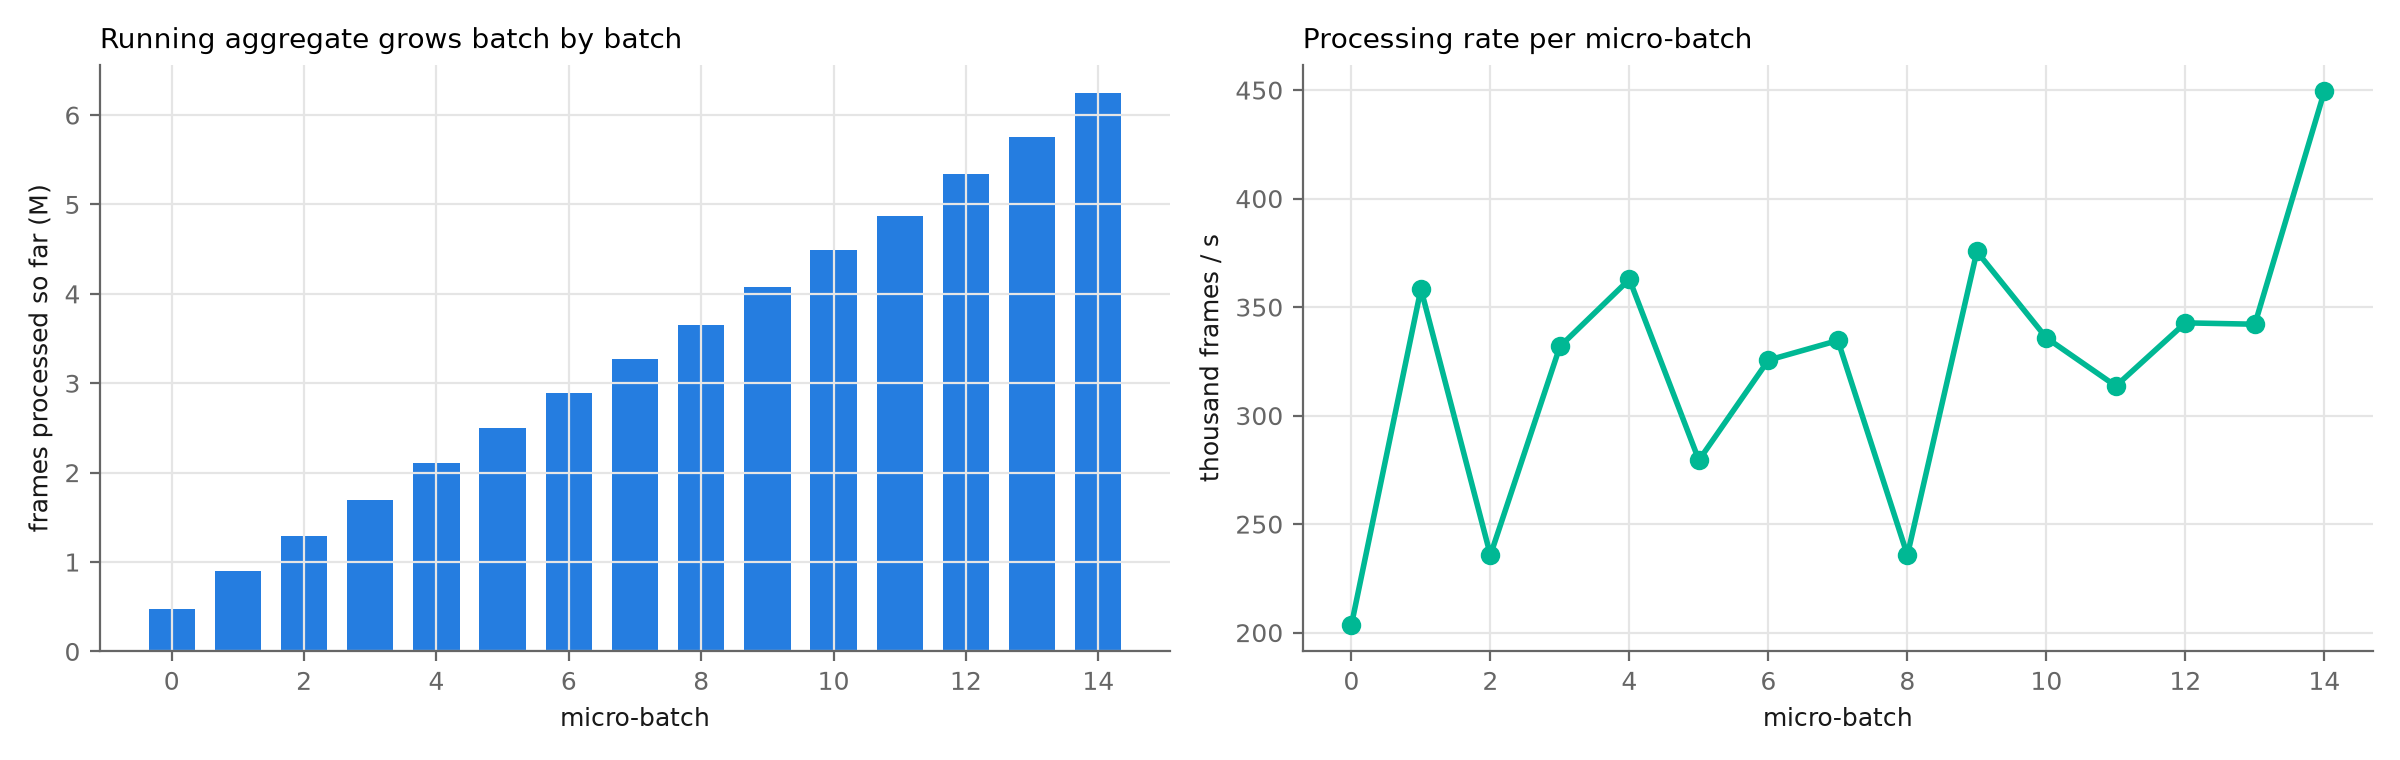

,line_group,frames,mean_speed,peak_speed
0,DL,2508284,2.202798,10.51
1,OL,3741886,1.674778,8.64


In [15]:
if STREAMING:
    src = TMP / "stream_src"; ck = TMP / "stream_ck"
    games_ = (spark.read.parquet(lgt_path).filter(F.col("season") == 2025).select("game_id").distinct()
              .orderBy("game_id").toPandas().game_id.values)
    n_files = 10 if QUICK else 30
    chunks = np.array_split(games_, n_files)
    base = spark.read.parquet(lgt_path).filter(F.col("season") == 2025).select("game_id", "nfl_id", "line_group", "s", "event")
    for i, ch in enumerate(chunks):
        (base.filter(F.col("game_id").isin([int(g) for g in ch])).coalesce(1)
             .write.mode("overwrite").parquet(str(src / f"part_{i:03d}")))
    files = sorted(src.rglob("*.parquet"))
    flat_src = TMP / "stream_files"; flat_src.mkdir()
    for i, f in enumerate(files):
        shutil.copy(f, flat_src / f"games_{i:03d}.parquet")
    stream = (spark.readStream.schema(base.schema).option("maxFilesPerTrigger", 2).parquet(str(flat_src))
                   .groupBy("line_group").agg(F.count("*").alias("frames"), F.avg("s").alias("mean_speed"),
                                              F.max("s").alias("peak_speed")))
    t0 = time.perf_counter()
    q = (stream.writeStream.format("memory").queryName("live_line_frames").outputMode("complete")
               .option("checkpointLocation", str(ck)).trigger(availableNow=True).start())
    q.awaitTermination(); t_stream = time.perf_counter() - t0
    prog = pd.DataFrame([dict(batch=p["batchId"], input_rows=p["numInputRows"],
                              rows_per_s=p.get("processedRowsPerSecond", np.nan),
                              batch_ms=p["durationMs"].get("triggerExecution", np.nan)) for p in q.recentProgress
                         if p["numInputRows"] > 0])
    live = spark.sql("select * from live_line_frames order by line_group").toPandas()
    batch = base.groupBy("line_group").agg(F.count("*").alias("frames")).orderBy("line_group").toPandas()
    print(f"{len(prog)} micro-batches, {prog.input_rows.sum():,} frames in {t_stream:.1f} s "
          f"({prog.input_rows.sum()/t_stream:,.0f} frames/s); streaming = batch counts: "
          f"{live.frames.tolist() == batch.frames.tolist()}")
    RESULTS.append(dict(experiment="E11", variant="Structured Streaming replay, 2 files / micro-batch", seconds=t_stream,
                        seconds_min=t_stream, runs=1, cores=MAXC, rows=int(prog.input_rows.sum())))
    prog.to_csv(C.TABLE_DIR / "10_streaming_progress.csv", index=False)
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
    axes[0].bar(prog.batch, prog.input_rows.cumsum() / 1e6, color=BLUE, width=0.7)
    axes[0].set_xlabel("micro-batch"); axes[0].set_ylabel("frames processed so far (M)")
    axes[0].set_title("Running aggregate grows batch by batch", loc="left", fontsize=10)
    axes[1].plot(prog.batch, prog.rows_per_s / 1e3, marker="o", ms=6, lw=2, color=AQUA)
    axes[1].set_xlabel("micro-batch"); axes[1].set_ylabel("thousand frames / s")
    axes[1].set_title("Processing rate per micro-batch", loc="left", fontsize=10)
    fig.tight_layout(); show(fig, "10_streaming.png")
    display(live)

## Summary: what each Spark choice is worth here
**Reading the numbers honestly.** Spark has a fixed cost per job (JVM, planning, scheduling tasks), so it does not win everywhere:
* On the **big steps** — 2+ GB of raw tracking CSV, 12M-frame window functions with two shuffles — the format, pruning, join, skew and core choices are worth multiples, and the same code runs unchanged on the full league tracking (all 22 players per snap, ~10× the linemen-only frames) or on a multi-node cluster.
* On the **small steps** — task tables of 15k–50k rows — a single-machine library would fit a model faster; there Spark's value is that the whole pipeline stays in one engine, with one set of Pipelines and player-grouped CV, and no hand-off between tools.
* Speedups flatten as cores grow (Amdahl): the serial share from the fit is the part no number of cores removes — driver work, Python ↔ JVM calls, small final stages.

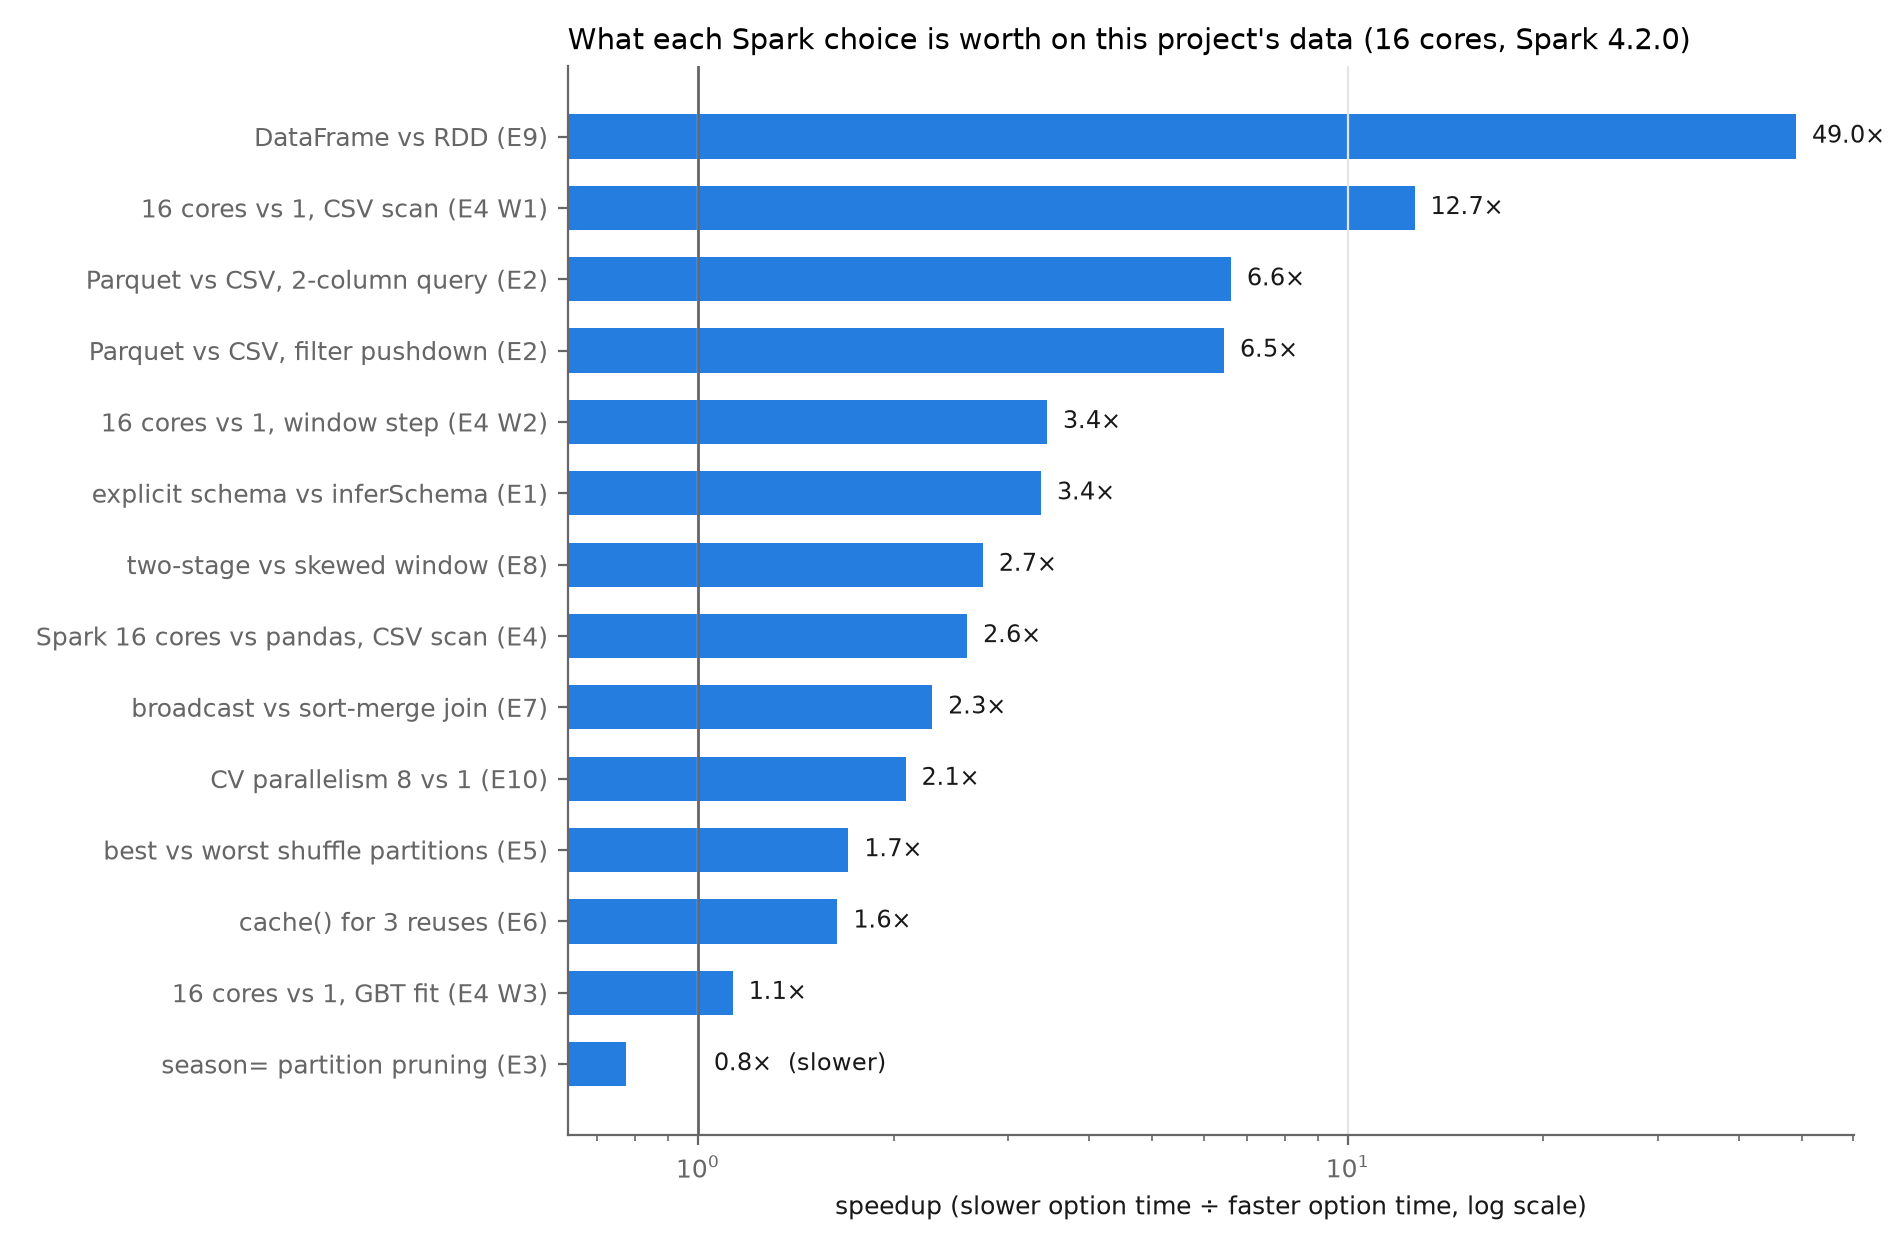

,choice,module,speedup
3,season= partition pruning (E3),M3/M4,0.78
6,"16 cores vs 1, GBT fit (E4 W3)",M8/M9,1.13
9,cache() for 3 reuses (E6),M2,1.64
8,best vs worst shuffle partitions (E5),M1,1.70
13,CV parallelism 8 vs 1 (E10),M8,2.09
10,broadcast vs sort-merge join (E7),M2,2.29
7,"Spark 16 cores vs pandas, CSV scan (E4)",M1,2.60
11,two-stage vs skewed window (E8),M5,2.74
0,explicit schema vs inferSchema (E1),M3,3.37
5,"16 cores vs 1, window step (E4 W2)",M1/M2,3.44


In [16]:
res = pd.DataFrame(RESULTS)
res.to_csv(C.TABLE_DIR / "10_benchmarks.csv", index=False)
def sec(exp, variant): return res.query("experiment == @exp and variant == @variant").seconds.iloc[0]
w = lambda s: res[(res.experiment == "E4") & res.variant.str.startswith(s)]
gains = [
    ("explicit schema vs inferSchema (E1)", "M3", sec("E1", "inferSchema=True") / sec("E1", "explicit StructType")),
    ("Parquet vs CSV, 2-column query (E2)", "M3", sec("E2", "CSV  · Q2 2 of 12 columns: avg(s) by player") / sec("E2", "Parquet · Q2 2 of 12 columns: avg(s) by player")),
    ("Parquet vs CSV, filter pushdown (E2)", "M3", sec("E2", "CSV  · Q3 filter event = ball_snap") / sec("E2", "Parquet · Q3 filter event = ball_snap")),
    ("season= partition pruning (E3)", "M3/M4", sec("E3", "unpartitioned table, filter season = 2025") / sec("E3", "season= folders, filter season = 2025")),
    (f"{MAXC} cores vs 1, CSV scan (E4 W1)", "M1/M2", scaling[scaling.workload.str.startswith("W1")].speedup.max()),
    (f"{MAXC} cores vs 1, window step (E4 W2)", "M1/M2", scaling[scaling.workload.str.startswith("W2")].speedup.max()),
    (f"{MAXC} cores vs 1, GBT fit (E4 W3)", "M8/M9", scaling[scaling.workload.str.startswith("W3")].speedup.max()),
    (f"Spark {MAXC} cores vs pandas, CSV scan (E4)", "M1", t_pandas / w("W1").query("p == @MAXC").seconds.iloc[0]),
    ("best vs worst shuffle partitions (E5)", "M1", e5.seconds.max() / e5.seconds.min()),
    ("cache() for 3 reuses (E6)", "M2", sec("E6", "no cache: 3 actions recompute the lineage") / sec("E6", "cache(): computed once, 2 actions read memory")),
    ("broadcast vs sort-merge join (E7)", "M2", sec("E7", "sort-merge join (shuffle both sides)") / sec("E7", "broadcast hash join")),
    ("two-stage vs skewed window (E8)", "M5", r_win["seconds"] / r_two["seconds"]),
    ("DataFrame vs RDD (E9)", "M2/M3", sec("E9", "RDD map + reduceByKey (Python lambdas)") / sec("E9", "DataFrame groupBy().agg(avg)")),
]
e10 = res[res.experiment == "E10"]
if len(e10) > 1:
    gains.append((f"CV parallelism {int(e10.parallelism.max())} vs 1 (E10)", "M8", e10.seconds.max() / e10.seconds.min()))
summary = pd.DataFrame(gains, columns=["choice", "module", "speedup"]).sort_values("speedup")
summary.to_csv(C.TABLE_DIR / "10_spark_choice_speedups.csv", index=False)

fig, ax = plt.subplots(figsize=(9.5, 0.36 * len(summary) + 1.2))
ax.barh(summary.choice, summary.speedup, color=BLUE, height=0.62)
ax.axvline(1, color=INK2, lw=1)
for i, v in enumerate(summary.speedup):
    ax.text(max(v, 1.0), i, f"  {v:.1f}×" + ("  (slower)" if v < 1 else ""), va="center", fontsize=8.5, color=INK)
ax.set_xscale("log"); ax.set_xlabel("speedup (slower option time ÷ faster option time, log scale)")
ax.grid(axis="y", visible=False)
ax.set_title(f"What each Spark choice is worth on this project's data ({MAXC} cores, Spark {spark.version})", loc="left", fontsize=10.5)
fig.tight_layout(); show(fig, "10_spark_choice_speedups.png")
summary.round(2)

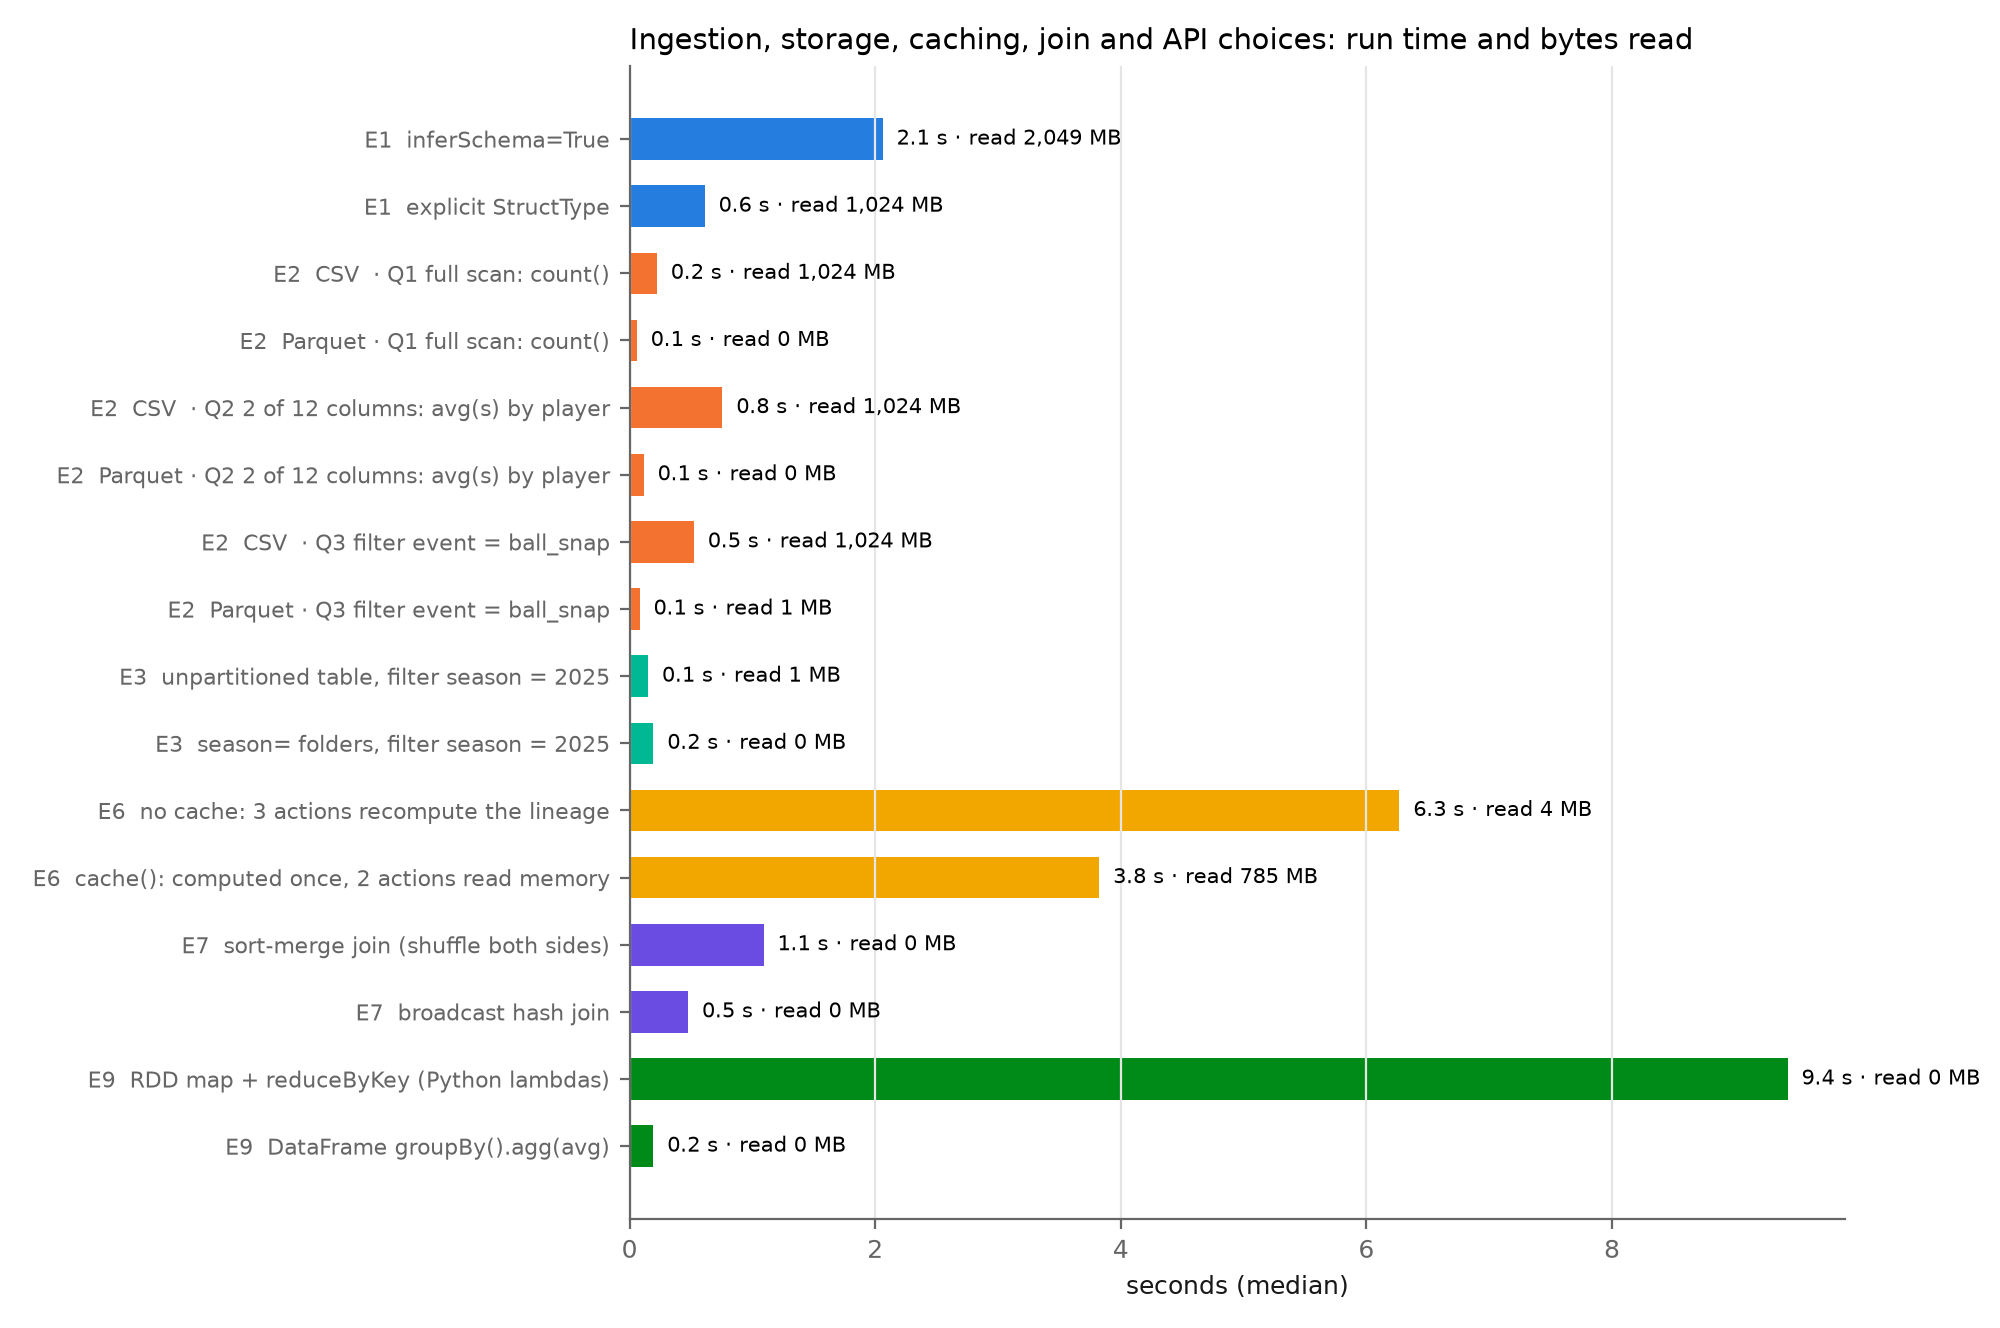

In [17]:
# one combined figure for the I/O experiments (E1-E3, E7, E9)
io = res[res.experiment.isin(["E1", "E2", "E3", "E6", "E7", "E9"])].copy()
fig, ax = plt.subplots(figsize=(10, 0.34 * len(io) + 1.2))
cols = {"E1": BLUE, "E2": ORANGE, "E3": AQUA, "E6": YELLOW, "E7": VIOLET, "E9": GREEN}
y = np.arange(len(io))[::-1]
ax.barh(y, io.seconds, color=[cols[e] for e in io.experiment], height=0.62)
ax.set_yticks(y, [f"{e}  {v}" for e, v in zip(io.experiment, io.variant)], fontsize=7.8)
for yy, v, mb in zip(y, io.seconds, io.input_mb):
    ax.text(v, yy, f"  {v:.1f} s" + (f" · read {mb:,.0f} MB" if mb and mb > 0 else ""), va="center", fontsize=7.6)
ax.set_xlabel("seconds (median)"); ax.grid(axis="y", visible=False)
ax.set_title("Ingestion, storage, caching, join and API choices: run time and bytes read", loc="left", fontsize=10.5)
fig.tight_layout(); show(fig, "10_io_and_execution_choices.png")

## Course concepts → where they are used in this project

In [18]:
concept_map = pd.DataFrame([
    ("M1", "MapReduce: map → shuffle → reduce, combiners", "every groupBy (partial + final HashAggregate), notebook 04 snap metrics", "E5, notebook 09 stage diagram"),
    ("M1/M2", "Driver, executors, task slots, local[*]", "run_pipeline.slurm: one 16-core node, local mode", "E4 strong scaling"),
    ("M2", "Lazy evaluation, DAG, stages", "each notebook builds plans; actions = count / write / fit", "notebook 09 physical plan"),
    ("M2", "persist() / cache()", "trait frames and task tables reused across CV fits", "E6"),
    ("M2/M3", "RDD vs DataFrame", "all code uses DataFrames + Spark SQL functions", "E9"),
    ("M3", "Explicit schemas, malformed records", "StructType for all 9 CSVs; multiLine + escape for play text", "E1"),
    ("M3", "Parquet, column pruning, predicate pushdown", "CSV → Parquet once in notebook 01", "E2"),
    ("M3/M4", "Partitioning, partition discovery", "partitionBy(season), partitionBy(drill_type)", "E3"),
    ("M5", "Data skew, hot spots, salting / two-stage", "frame work keyed by (game, play, player), not player", "E8"),
    ("M6", "Sparse vectors", "OneHotEncoder → sparse feature vectors", "E10"),
    ("M8", "ML Pipelines, CrossValidator, feature utilities", "9 pipelines × 5 tasks, player-grouped foldCol", "E10, notebook 06"),
    ("M9", "Data-parallel training", "LR / RF / GBT fits distributed over partitions", "E4 W3, E10"),
    ("M11", "Structured Streaming, micro-batches", "replay of tracking frames as a stream", "E11"),
    ("M12", "Governance", "CC BY-NC data (non-commercial use); Combine clips anonymous; raw data never copied into outputs", "—"),
], columns=["module", "concept", "where in this project", "measured in"])
concept_map.to_csv(C.TABLE_DIR / "10_course_concept_map.csv", index=False)
concept_map

,module,concept,where in this project,measured in
0,M1,"MapReduce: map → shuffle → reduce, combiners","every groupBy (partial + final HashAggregate),...","E5, notebook 09 stage diagram"
1,M1/M2,"Driver, executors, task slots, local[*]","run_pipeline.slurm: one 16-core node, local mode",E4 strong scaling
2,M2,"Lazy evaluation, DAG, stages",each notebook builds plans; actions = count / ...,notebook 09 physical plan
3,M2,persist() / cache(),trait frames and task tables reused across CV ...,E6
4,M2/M3,RDD vs DataFrame,all code uses DataFrames + Spark SQL functions,E9
5,M3,"Explicit schemas, malformed records",StructType for all 9 CSVs; multiLine + escape ...,E1
6,M3,"Parquet, column pruning, predicate pushdown",CSV → Parquet once in notebook 01,E2
7,M3/M4,"Partitioning, partition discovery","partitionBy(season), partitionBy(drill_type)",E3
8,M5,"Data skew, hot spots, salting / two-stage","frame work keyed by (game, play, player), not ...",E8
9,M6,Sparse vectors,OneHotEncoder → sparse feature vectors,E10


In [19]:
_spark.stop()
shutil.rmtree(TMP, ignore_errors=True)
print("benchmark rows:", len(res), "| tables: 10_benchmarks.csv, 10_core_scaling.csv, 10_spark_choice_speedups.csv, 10_course_concept_map.csv")

benchmark rows: 46 | tables: 10_benchmarks.csv, 10_core_scaling.csv, 10_spark_choice_speedups.csv, 10_course_concept_map.csv
